<a href="https://colab.research.google.com/github/lulusbersamasama-TE/solar-ai-mppt-optimization/blob/main/notebooks/04_verification_and_sensitivity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 — Mathematical Verification, Sensitivity and Robustness

**Course-aligned verification supplement**, not a replacement for Notebooks 01–03. Execute 01 → 02 → 03 first, then this notebook. Uses original user-provided PV I–V curves and held-out weather predictions; no hardware is involved.

**Research questions (RQs)**

- **RQ1**: Does forecasting beat persistence, including during rapid irradiance changes?
- **RQ2**: Does better V_GMPP prediction translate to lower power loss on held-out P–V curves, and how much does spatial shading input matter?
- **RQ3**: Is P&O/AI performance robust to initial voltage and perturbation step? Does the effect survive a P&O parameter search performed *only on validation curves*?
- **RQ4**: Does adding RF irradiance forecasting increase MPPT efficiency relative to AI + persistence, under the **same six-section estimation and action rules**?

**Fairness caveat**: P&O uses only power observations, while AI uses six irradiance estimates. A P&O–AI gap must NOT be interpreted as pure algorithm superiority with sensor parity. No converter losses, physical time steps or switching dynamics are modeled.

Evidence generated: data integrity, exact P–V power-loss, mean-irradiance input ablation, transient-conditioned weather error, validation-selected P&O sensitivity, paired episode bootstrap confidence intervals, grouped split stability and a verification summary.

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
RNG = np.random.default_rng(SEED)

# Colab setup: same Drive layout as previous notebooks.
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

candidates = [
    Path('/content/drive/MyDrive/solar_ai_mppt_project'),
    Path('/content/solar_ai_mppt_project'),
    Path.cwd(),
    Path.cwd().parent,
]
ROOT = next((d for d in candidates
             if (d/'data'/'pv_database_summary_extract.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError(
        'Copy the three derived datasets to MyDrive/solar_ai_mppt_project/data/'
    )
DATA, OUT = ROOT/'data', ROOT/'outputs'
OUT.mkdir(parents=True, exist_ok=True)
required = [
    DATA/'pv_database_summary_extract.csv',
    DATA/'pv_iv_curves_0p1V.npz',
    OUT/'gmpp_models.joblib',
    OUT/'gmpp_splits.csv',
    OUT/'irradiance_test_forecasts.csv.gz'
]
missing = [str(x) for x in required if not x.exists()]
if missing:
    raise FileNotFoundError(
        'Run notebooks 01 and 02 first. Missing:\n' + '\n'.join(missing)
    )
print('Root:', ROOT)
print('All prerequisite artifacts present.')

Mounted at /content/drive
Root: /content/drive/MyDrive/solar_ai_mppt_project
All prerequisite artifacts present.


## A. Dataset and electrical ground-truth integrity

Power is calculated from **actual supplied I–V sweep samples**, not fabricated from a single radiation-to-power coefficient. Validate ordering, row alignment, label consistency, global power maxima, and whether any maximum lies on the grid boundary.

In [2]:
meta = pd.read_csv(DATA/'pv_database_summary_extract.csv')
meta['curve_id'] = meta['Curve'].astype(int)
splits = pd.read_csv(OUT/'gmpp_splits.csv')
meta = meta.merge(splits, on='curve_id', validate='one_to_one')
F = [f'Section_{i}_Wm2' for i in range(1,7)]
assert meta.curve_id.is_unique
assert set(F + ['Vmp_V','Imp_A','Pmax_W','split']).issubset(meta.columns)

source = np.load(DATA/'pv_iv_curves_0p1V.npz')
V = np.asarray(source['voltage'], dtype=float)
I = np.asarray(source['current'], dtype=float)
curve_ids = np.asarray(source['curve_id'], dtype=int)
assert len(curve_ids) == I.shape[0] == len(meta)
assert I.shape[1] == len(V) and np.all(np.diff(V) > 0)
assert len(np.unique(curve_ids)) == len(curve_ids)
assert set(curve_ids) == set(meta.curve_id)

id_to_row = {int(cid): j for j,cid in enumerate(curve_ids)}
P = V[None,:] * I
best_idx = P.argmax(axis=1)
P_best = P[np.arange(len(curve_ids)), best_idx]
V_best = V[best_idx]
meta = meta.set_index('curve_id', drop=False)
label_P = meta.loc[curve_ids, 'Pmax_W'].to_numpy()
p_label_err = np.abs(P_best-label_P)
groups = meta[F[:5]].astype(int).astype(str).agg('|'.join,axis=1)
for a,b in [('train','validation'),('train','test'),('validation','test')]:
    assert not (set(groups[meta.split==a]) & set(groups[meta.split==b]))
print('Curves:',len(curve_ids),'Voltage samples:',len(V))
print('I min/max:',I.min(),I.max())
print('Abs difference to full-resolution Pmax (W):',
      'median',np.median(p_label_err),'p95',np.percentile(p_label_err,95),
      'max',p_label_err.max())
boundary = (best_idx==0)|(best_idx==len(V)-1)
print('Maxima on sweep boundary:',int(boundary.sum()), '(',round(boundary.mean()*100,3),'%)')
print('Configuration-group independence: PASS')
assert np.all(np.isfinite(P)) and np.all(P_best>0)
assert np.median(p_label_err)<0.1
integrity = pd.DataFrame([{
    'curve_count':len(curve_ids),'voltage_samples_per_curve':len(V),
    'median_power_grid_error_W':float(np.median(p_label_err)),
    'p95_power_grid_error_W':float(np.percentile(p_label_err,95)),
    'max_power_grid_error_W':float(p_label_err.max()),
    'boundary_maxima_count':int(boundary.sum()),
    'minimum_current_A':float(I.min())
}])
integrity.to_csv(OUT/'verification_integrity.csv',index=False)

Curves: 14400 Voltage samples: 415
I min/max: 0.40410086512565613 5.216301441192627
Abs difference to full-resolution Pmax (W): median 0.0015352886693449364 p95 0.005678937939987347 max 0.39826454848379456
Maxima on sweep boundary: 0 ( 0.0 %)
Configuration-group independence: PASS


## B. Mathematical verification — voltage error versus harvested-power loss

For each held-out curve, compare the **actual** power at the predicted operating voltage (using I–V interpolation), not just the regression error.

```
P(V) = V I(V)
V* = arg max_V P(V)
eV = Vhat - V*
L_P (%) = 100 [P(V*) - P(Vhat)] / P(V*)
```

Near an isolated smooth peak, Taylor expansion gives approximately `P(V*) - P(V*+e) ≈ -0.5 P''(V*) e²`. Under partial shading this local argument **does not transfer across different peaks**; always use the exact sampled P–V curve for verification.

      model  curves  voltage_mae_V  power_loss_mean_pct  power_loss_median_pct  power_loss_p95_pct  reached_98pct_P_rate
     linear    2160          3.315                8.194                  5.878              24.938                23.472
rf_6section    2160          0.301                0.392                  0.016               1.708                95.231
Interpolated power > grid maximum (numeric edge cases): 0


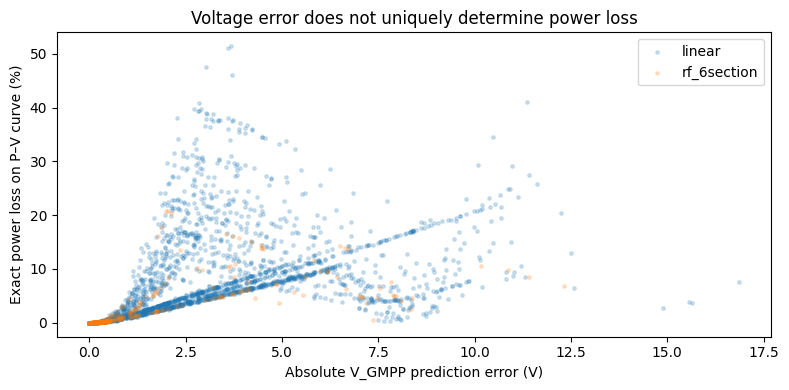

In [3]:
model_bundle = joblib.load(OUT/'gmpp_models.joblib')
assert list(model_bundle['feature_columns']) == F
RF = model_bundle['random_forest']
LIN = model_bundle['linear']
test = meta.loc[meta.split=='test'].copy()
train = meta.loc[meta.split=='train'].copy()
valid = meta.loc[meta.split=='validation'].copy()

def current_and_power(cid, voltage):
    cid = int(cid)
    vol = float(np.clip(voltage, V[0], V[-1]))
    curr = float(np.interp(vol, V, I[id_to_row[cid]]))
    return curr, vol*curr

def powerloss_frame(rows, model, label):
    voltage_pred = np.clip(model.predict(rows[F]), V[0], V[-1])
    results=[]
    for cid,vhat,vtrue in zip(rows.curve_id,voltage_pred,rows.Vmp_V):
        j=id_to_row[int(cid)]
        p_hat=current_and_power(cid,vhat)[1]
        pideal=float(P_best[j])
        results.append({
            'curve_id':int(cid),'model':label,'Vtrue_V':float(vtrue),
            'Vpred_V':float(vhat),'Verror_V':float(vhat-vtrue),
            'Pideal_W':pideal,'Ppred_W':p_hat,
            # Clip only tiny interpolation overshoot; retain raw signed loss too.
            'power_loss_pct_raw':100*(pideal-p_hat)/pideal,
            'power_loss_pct':100*max(0.,(pideal-p_hat)/pideal),
            'within_98pct_P':bool(p_hat >= 0.98*pideal),
        })
    return pd.DataFrame(results)

perf = pd.concat([
    powerloss_frame(test, LIN, 'linear'),
    powerloss_frame(test, RF, 'rf_6section')
],ignore_index=True)
power_metrics = perf.groupby('model').agg(
    curves=('curve_id','size'),
    voltage_mae_V=('Verror_V',lambda s: np.mean(np.abs(s))),
    power_loss_mean_pct=('power_loss_pct','mean'),
    power_loss_median_pct=('power_loss_pct','median'),
    power_loss_p95_pct=('power_loss_pct',lambda s: np.percentile(s,95)),
    reached_98pct_P_rate=('within_98pct_P','mean')
).reset_index()
power_metrics['reached_98pct_P_rate'] *= 100
print(power_metrics.round(3).to_string(index=False))
print('Interpolated power > grid maximum (numeric edge cases):',
      int((perf.power_loss_pct_raw < -0.001).sum()))
perf.to_csv(OUT/'verification_voltage_power_loss_per_curve.csv',index=False)
power_metrics.to_csv(OUT/'verification_voltage_power_loss_summary.csv',index=False)

fig,ax=plt.subplots(figsize=(8,4))
for label,g in perf.groupby('model'):
    ax.scatter(abs(g.Verror_V),g.power_loss_pct,alpha=.20,s=6,label=label)
ax.set(xlabel='Absolute V_GMPP prediction error (V)',
       ylabel='Exact power loss on P–V curve (%)',
       title='Voltage error does not uniquely determine power loss')
ax.legend()
plt.tight_layout()
fig.savefig(OUT/'verification_voltage_vs_power_loss.png',dpi=150)
plt.show()

## C. Sensor-information ablation

The original AI model has access to six spatial irradiance measurements, whereas P&O only observes terminal electrical power. We cannot claim sensor parity. Instead, quantify the gain from spatial irradiance by training the **same RF class and parameters** with one scalar (mean section irradiance). This is an information ablation, not a fully sensor-matched P&O comparison.

In [4]:
train1 = pd.DataFrame({'G_mean':train[F].mean(axis=1)})
test1 = pd.DataFrame({'G_mean':test[F].mean(axis=1)})
RF_MEAN = RandomForestRegressor(
    n_estimators=180,max_depth=20,min_samples_leaf=2,
    n_jobs=-1,random_state=SEED)
RF_MEAN.fit(train1,train.Vmp_V)

vhat = np.clip(RF_MEAN.predict(test1),V[0],V[-1])
rows=[]
for cid,vtrue,vpred in zip(test.curve_id,test.Vmp_V,vhat):
    j=id_to_row[int(cid)]
    pp=current_and_power(cid,vpred)[1]
    rows.append({'curve_id':int(cid),'Verror_V':float(vpred-vtrue),
        'power_loss_pct':max(0.,100*(float(P_best[j])-pp)/float(P_best[j]))})
abl=pd.DataFrame(rows)
ablation=pd.DataFrame([
    {'model':'RF (6 section G)','V_RMSE_V':np.sqrt(np.mean(
        perf.loc[perf.model=='rf_6section','Verror_V'].to_numpy()**2)),
     'mean_power_loss_pct':perf.loc[perf.model=='rf_6section','power_loss_pct'].mean()},
    {'model':'RF (mean G only)','V_RMSE_V':np.sqrt(np.mean(abl.Verror_V**2)),
     'mean_power_loss_pct':abl.power_loss_pct.mean()}
])
print(ablation.round(3).to_string(index=False))
ablation.to_csv(OUT/'verification_spatial_sensor_ablation.csv',index=False)

           model  V_RMSE_V  mean_power_loss_pct
RF (6 section G)     1.072                0.392
RF (mean G only)     4.732               10.288


## D. Forecast robustness: rapid transients and overlap with PV database

The 5-minute realized GHI change `|G(t+5) - G(t)|` defines a retrospective test subgroup (**not** an inference feature). We report MAE/RMSE separately for the top 10% fastest-changing windows and for all windows. Check the narrow high-irradiance domain used by Notebook 03, too.

              subset         model      N  G_change_top10_threshold_Wm2  MAE_Wm2  RMSE_Wm2
            all_test   persistence 225225                       136.481   53.062   116.346
            all_test random_forest 225225                       136.481   49.824   102.149
            all_test        linear 225225                       136.481   58.500   108.103
top_10pct_abs_change   persistence  22523                       136.481  308.901   351.262
top_10pct_abs_change random_forest  22523                       136.481  239.184   278.073
top_10pct_abs_change        linear  22523                       136.481  262.883   304.359
     remaining_90pct   persistence 202702                       136.481   24.635    36.479
     remaining_90pct random_forest 202702                       136.481   28.784    54.791
     remaining_90pct        linear 202702                       136.481   35.791    51.881
High-GHI weather windows usable for Test B: 15590/225225 (6.92%)


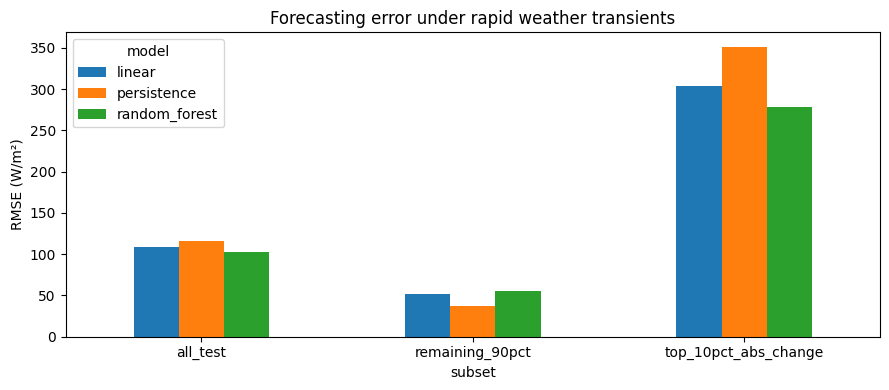

In [5]:
fc = pd.read_csv(OUT/'irradiance_test_forecasts.csv.gz',
                 parse_dates=['timestamp','target_timestamp'])
assert (fc.target_timestamp-fc.timestamp).eq(pd.Timedelta(minutes=5)).all()
fc['abs_change'] = (fc.ghi_true_5min-fc.ghi_now).abs()
q90=float(fc.abs_change.quantile(.90))
fc['rapid'] = fc.abs_change >= q90
weather_rows=[]
for tag,part in [
    ('all_test',fc),('top_10pct_abs_change',fc[fc.rapid]),
    ('remaining_90pct',fc[~fc.rapid])
]:
    for name,col in [
        ('persistence','ghi_pred_persistence'),
        ('random_forest','ghi_pred_rf'),
        ('linear','ghi_pred_linear')
    ]:
        weather_rows.append({
            'subset':tag,'model':name,'N':len(part),
            'G_change_top10_threshold_Wm2':q90,
            'MAE_Wm2':mean_absolute_error(part.ghi_true_5min,part[col]),
            'RMSE_Wm2':np.sqrt(mean_squared_error(part.ghi_true_5min,part[col]))
        })
weather_metrics=pd.DataFrame(weather_rows)
print(weather_metrics.round(3).to_string(index=False))
mask = (fc.ghi_now.between(850,1050) &
        fc.ghi_true_5min.between(850,1050) &
        fc.ghi_pred_rf.between(850,1050) &
        fc.ghi_pred_persistence.between(850,1050))
print(f'High-GHI weather windows usable for Test B: {mask.sum()}/{len(fc)} ({mask.mean()*100:.2f}%)')
weather_metrics.to_csv(OUT/'verification_transient_weather_metrics.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4))
tmp=weather_metrics.pivot(index='subset',columns='model',values='RMSE_Wm2')
tmp.plot(kind='bar',ax=ax,rot=0)
ax.set(ylabel='RMSE (W/m²)',title='Forecasting error under rapid weather transients')
plt.tight_layout()
fig.savefig(OUT/'verification_transient_forecast.png',dpi=150)
plt.show()

## E. P&O sensitivity with **validation-only** hyperparameter selection

Compare starting voltages 15, 20, 27, 35, 40 V with perturbations 0.25, 0.5, 1, 2 V per iteration. All candidate settings are evaluated **only on the validation curves** to select the best P&O configuration; the held-out test curves are used afterward.

**Important alignment improvement over Notebook 03:** Both P&O and AI powers are measured at their **current** voltages before executing the next voltage update. Thus both receive the same number of observation/update opportunities (30). AI still has privileged six-section irradiance information.

For each static curve, compare `sum(P_tracking)/[N_steps * P_GMPP]`. This is not electrical energy without specifying a real control period.

Best VALIDATION-SELECTED P&O: 27.0 V, step: 1.0 V
 start_V  step_V  validation_efficiency_pct  validation_final_hit_pct
    27.0    1.00                     93.018                    35.000
    27.0    0.50                     92.733                    53.333
    20.0    2.00                     92.569                    50.000
    27.0    2.00                     91.676                    30.833
    27.0    0.25                     91.432                    45.000
    20.0    1.00                     90.685                    40.833
    20.0    0.50                     88.171                    40.000
    15.0    2.00                     86.920                    21.667
    20.0    0.25                     84.679                    21.667
    35.0    0.50                     83.630                    45.000
    15.0    1.00                     83.577                    28.333
    35.0    1.00                     83.491                    30.000
    35.0    0.25                     82.

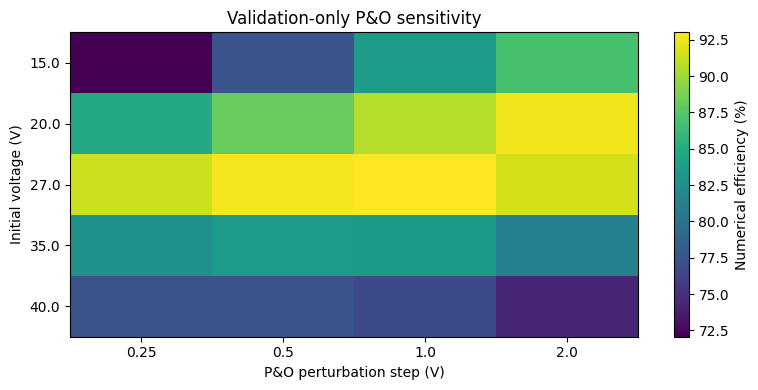

In [6]:
def static_controller_run(cid, strategy='po', reference_v=None,
                          start_v=27., voltage_step=1., nsteps=30):
    cid=int(cid)
    v=float(np.clip(start_v,V[0],V[-1]))
    direction=1.
    previous=None
    powers=[]; voltages=[]
    for k in range(nsteps):
        pw=current_and_power(cid,v)[1]
        powers.append(pw);voltages.append(v)
        if strategy=='po':
            if previous is not None and pw<previous:
                direction=-direction
            previous=pw
            v=float(np.clip(v+voltage_step*direction,V[0],V[-1]))
        elif strategy=='ai':
            if reference_v is None: raise ValueError('AI requires a target')
            v=float(np.clip(v+np.clip(reference_v-v,-voltage_step,voltage_step),
                            V[0],V[-1]))
        else:
            raise ValueError('Unknown strategy')
    return np.asarray(powers),np.asarray(voltages)

val_cases=valid.sample(n=min(len(valid),120),random_state=SEED)
test_cases=test.sample(n=min(len(test),120),random_state=SEED)
V0_VALUES=[15.,20.,27.,35.,40.]
STEPS=[.25,.5,1.,2.]
NSTEPS=30

def evaluate_one_configuration(cases,v0,step):
    po_sums=[]; ideal_sums=[]; hit=[]
    for cid in cases.curve_id:
        pw,_=static_controller_run(cid,'po',start_v=v0,
                                    voltage_step=step,nsteps=NSTEPS)
        pstar=float(P_best[id_to_row[int(cid)]])
        po_sums.append(float(pw.sum()))
        ideal_sums.append(pstar*NSTEPS)
        hit.append(pw[-1]>=.98*pstar)
    return (100*sum(po_sums)/sum(ideal_sums),100*np.mean(hit))

scan=[]
for v0 in V0_VALUES:
    for step in STEPS:
        eta,hit=evaluate_one_configuration(val_cases,v0,step)
        scan.append({'start_V':v0,'step_V':step,
                     'validation_efficiency_pct':eta,
                     'validation_final_hit_pct':hit})
sensitivity=pd.DataFrame(scan).sort_values('validation_efficiency_pct',ascending=False)
best=sensitivity.iloc[0]
BEST_V0=float(best.start_V); BEST_STEP=float(best.step_V)
print('Best VALIDATION-SELECTED P&O:',BEST_V0,'V, step:',BEST_STEP,'V')
print(sensitivity.round(3).to_string(index=False))
sensitivity.to_csv(OUT/'verification_po_validation_grid.csv',index=False)

fig,ax=plt.subplots(figsize=(8,4))
pivot=sensitivity.pivot(index='start_V',columns='step_V',
                        values='validation_efficiency_pct')
im=ax.imshow(pivot.to_numpy(),aspect='auto')
ax.set(xticks=np.arange(len(pivot.columns)),
       xticklabels=pivot.columns,
       yticks=np.arange(len(pivot.index)),
       yticklabels=pivot.index,
       xlabel='P&O perturbation step (V)',ylabel='Initial voltage (V)',
       title='Validation-only P&O sensitivity')
plt.colorbar(im,ax=ax,label='Numerical efficiency (%)')
plt.tight_layout()
fig.savefig(OUT/'verification_po_sensitivity_heatmap.png',dpi=150)
plt.show()

## F. Held-out comparison, uncertainty, and update timing

Run on the **same 120 test curves**: historical baseline P&O (27 V, 1 V), validation-tuned P&O, RF-AI (27 V, 1 V), RF-AI at validation-tuned initialization and step. AI targets are predicted once from the six irradiance sections and held fixed over each static episode.

Bootstrap the **whole curve/episode**, not individual correlated control iterations, to obtain a 95% confidence interval for the numerical tracking-efficiency difference. This interval characterizes these sampled episodes only; it does not establish field-device superiority.

In [7]:
pred_test=pd.DataFrame({'curve_id':test_cases.curve_id.to_numpy(),
                        'rf_target_V':np.clip(RF.predict(test_cases[F]),V[0],V[-1])})
target_map=dict(zip(pred_test.curve_id.astype(int),pred_test.rf_target_V))
records=[]
for cid in test_cases.curve_id:
    cid=int(cid)
    ideal=float(P_best[id_to_row[cid]])*NSTEPS
    for label,kind,start,step in [
        ('po_original','po',27.,1.),
        ('po_val_tuned','po',BEST_V0,BEST_STEP),
        ('ai_rf_original','ai',27.,1.),
        ('ai_rf_same_tuned','ai',BEST_V0,BEST_STEP),
    ]:
        pw,vv=static_controller_run(cid,kind,
                reference_v=target_map[cid] if kind=='ai' else None,
                start_v=start,voltage_step=step,nsteps=NSTEPS)
        records.append({'curve_id':cid,'controller':label,
            'sum_power_W_iterations':pw.sum(),
            'ideal_sum_W_iterations':ideal,
            'final_hit':pw[-1]>=.98*(ideal/NSTEPS),
            'last10_voltage_peak_to_peak_V':np.ptp(vv[-10:])})
test_runs=pd.DataFrame(records)
test_summary=test_runs.groupby('controller').agg(
    n=('curve_id','size'),
    sum_tracking=('sum_power_W_iterations','sum'),
    sum_ideal=('ideal_sum_W_iterations','sum'),
    final_hit_rate=('final_hit','mean'),
    last10_voltage_ptp=('last10_voltage_peak_to_peak_V','mean'))
test_summary['efficiency_pct']=100*test_summary.sum_tracking/test_summary.sum_ideal
test_summary['final_hit_rate_pct']=100*test_summary.final_hit_rate
print(test_summary[['n','efficiency_pct','final_hit_rate_pct',
                    'last10_voltage_ptp']].round(3).to_string())

wide=test_runs.pivot(index='curve_id',columns='controller',
                     values='sum_power_W_iterations')
ideal_by_curve=test_runs.drop_duplicates('curve_id').set_index('curve_id')[
    'ideal_sum_W_iterations'].loc[wide.index].to_numpy()

def paired_efficiency_bootstrap(a,b,denominator,nboot=2000,seed=42):
    rng=np.random.default_rng(seed)
    a=np.asarray(a,float);b=np.asarray(b,float);denominator=np.asarray(denominator,float)
    assert len(a)==len(b)==len(denominator)
    differences=[]
    for _ in range(nboot):
        idx=rng.integers(0,len(a),len(a))
        differences.append(100*sum(a[idx]-b[idx])/sum(denominator[idx]))
    return (100*sum(a-b)/sum(denominator),
            float(np.percentile(differences,2.5)),
            float(np.percentile(differences,97.5)))

boot_rows=[]
for first,second in [
    ('ai_rf_original','po_original'),
    ('ai_rf_same_tuned','po_val_tuned'),
    ('po_val_tuned','po_original'),
]:
    effect,lo,hi=paired_efficiency_bootstrap(
        wide[first].to_numpy(),wide[second].to_numpy(),
        ideal_by_curve)
    boot_rows.append({'comparison':f'{first} minus {second}',
                      'difference_pp':effect,
                      'bootstrap95_low_pp':lo,
                      'bootstrap95_high_pp':hi,
                      'N_curves':len(wide)})
ci=pd.DataFrame(boot_rows)
print(ci.round(4).to_string(index=False))
ci.to_csv(OUT/'verification_static_paired_bootstrap.csv',index=False)
test_runs.to_csv(OUT/'verification_static_controller_runs.csv',index=False)
test_summary.to_csv(OUT/'verification_static_controller_summary.csv')

                    n  efficiency_pct  final_hit_rate_pct  last10_voltage_ptp
controller                                                                   
ai_rf_original    120          98.079              96.667                 0.0
ai_rf_same_tuned  120          98.079              96.667                 0.0
po_original       120          94.861              45.000                 2.0
po_val_tuned      120          94.861              45.000                 2.0
                         comparison  difference_pp  bootstrap95_low_pp  bootstrap95_high_pp  N_curves
   ai_rf_original minus po_original         3.2182              2.2117               4.3687       120
ai_rf_same_tuned minus po_val_tuned         3.2182              2.2117               4.3687       120
     po_val_tuned minus po_original         0.0000              0.0000               0.0000       120


## G. Optional: paired confidence interval for forecasting benefit in Notebook 03

This evaluates **AI + RF Forecast minus AI + Persistence** on the exact same synthetic episodes from Notebook 03, using whole episodes as bootstrap units. These differences are conditional on the **synthetic** shading/matching construction. AI + oracle is diagnostic, not deployable.

In [8]:
integrated_path=OUT/'forecast_integrated_mppt_log.csv'
if integrated_path.exists():
    log=pd.read_csv(integrated_path)
    needed={'event','ai_forecast_power','ai_persist_power','ideal_power'}
    assert needed.issubset(log.columns)
    by_event=log.groupby('event',sort=True).agg(
        forecast=('ai_forecast_power','sum'),
        persistence=('ai_persist_power','sum'),
        ideal=('ideal_power','sum'))
    effect,lo,hi=paired_efficiency_bootstrap(
        by_event.forecast.to_numpy(),
        by_event.persistence.to_numpy(),
        by_event.ideal.to_numpy(),seed=SEED+1)
    print('AI forecast - AI persistence (pp):',
          round(effect,5),'95% episode bootstrap CI:',
          (round(lo,5),round(hi,5)),'N',len(by_event))
    pd.DataFrame([{'difference_pp':effect,'low95_pp':lo,
                   'high95_pp':hi,'episode_count':len(by_event)}
                 ]).to_csv(OUT/'verification_forecast_increment_CI.csv',index=False)
    # A CI crossing 0 does not prove exact equivalence.
else:
    print('Missing forecast-integrated episode log. Rerun Notebook 03 to '
          'generate forecast_integrated_mppt_log.csv before this optional analysis.')

AI forecast - AI persistence (pp): -0.04229 95% episode bootstrap CI: (-0.2243, 0.13452) N 75


## H. Repeated randomized *group-split* robustness of GMPP regression

Three independent group-based splits with the same Random Forest hyperparameters test whether the result depends strongly on which irradiance configurations happen to be withheld. This repeats training and can take a few minutes on CPU. **It does not claim independent field deployment generalization.**

In [9]:
new_groups=meta[F[:5]].astype(int).astype(str).agg('|'.join,axis=1)
stability=[]
for seed in [7,42,2026]:
    splitter=GroupShuffleSplit(n_splits=1,test_size=.15,random_state=seed)
    idx_train,idx_test=next(splitter.split(meta,groups=new_groups))
    tr=meta.iloc[idx_train];te=meta.iloc[idx_test]
    model=RandomForestRegressor(n_estimators=180,max_depth=20,
          min_samples_leaf=2,n_jobs=-1,random_state=seed)
    model.fit(tr[F],tr.Vmp_V)
    yp=model.predict(te[F])
    stability.append({'seed':seed,'train_curves':len(tr),'test_curves':len(te),
        'RMSE_V':np.sqrt(mean_squared_error(te.Vmp_V,yp)),
        'MAE_V':mean_absolute_error(te.Vmp_V,yp),
        'R2':r2_score(te.Vmp_V,yp)})
stability=pd.DataFrame(stability)
print(stability.round(4).to_string(index=False))
print('RMSE mean ± sample SD:',
      round(stability.RMSE_V.mean(),4), '±',
      round(stability.RMSE_V.std(ddof=1),4),'V')
stability.to_csv(OUT/'verification_group_split_stability.csv',index=False)

 seed  train_curves  test_curves  RMSE_V  MAE_V     R2
    7         12240         2160  1.3535 0.3346 0.9402
   42         12240         2160  1.0345 0.2752 0.9611
 2026         12240         2160  1.0050 0.2566 0.9657
RMSE mean ± sample SD: 1.131 ± 0.1933 V


## I. Audit output checklist and scientific limitations

**Interpretation rules**:
- Faster weather prediction MAE does not imply higher MPPT power.
- A six-section irradiance AI has additional sensing information compared with pure terminal-voltage/current P&O. A causal algorithm comparison with sensor parity is **not supported**.
- The modified controller comparison aligns the voltage-measurement timing; its figures need not match Notebook 03's legacy evaluation.
- P&O hyperparameter selection MUST use validation only; test curves are reserved for the final comparison.
- Bootstrap CIs cover the sampled curves/episodes, not uncertainty in converter physical dynamics or PV installation diversity.
- Numerical efficiency ratios assume equal controller-step duration. They are **not hardware energy conversion efficiency**.
- `P(V*)` is a grid-based maximum; record power-grid mismatch and any maxima at measurement boundaries.
- Synthetic weather-to-PV linking and oracle-based tests do not constitute real-world dynamic irradiance measurements.

Run this final cell to list evidence files for the report. Document **actual** team contributions in GitHub PRs and peer-reflection files; do not infer individual work from a shared account.

In [10]:
prefix='verification_'
evidence=sorted(p for p in OUT.glob(prefix+'*') if p.is_file())
for item in evidence:
    print(item.name, f'({item.stat().st_size/1024:.1f} KiB)')
assert all((OUT/f).exists() for f in [
    'verification_integrity.csv',
    'verification_voltage_power_loss_summary.csv',
    'verification_spatial_sensor_ablation.csv',
    'verification_transient_weather_metrics.csv',
    'verification_po_validation_grid.csv',
    'verification_static_paired_bootstrap.csv',
    'verification_group_split_stability.csv',
])
print('Required verification evidence files found.')
print('NOTE: independent review, contribution records and physical validation remain separate.')

verification_forecast_increment_CI.csv (0.1 KiB)
verification_group_split_stability.csv (0.3 KiB)
verification_integrity.csv (0.2 KiB)
verification_po_sensitivity_heatmap.png (48.9 KiB)
verification_po_validation_grid.csv (0.8 KiB)
verification_spatial_sensor_ablation.csv (0.1 KiB)
verification_static_controller_runs.csv (30.9 KiB)
verification_static_controller_summary.csv (0.5 KiB)
verification_static_paired_bootstrap.csv (0.3 KiB)
verification_transient_forecast.png (44.3 KiB)
verification_transient_weather_metrics.csv (0.8 KiB)
verification_voltage_power_loss_per_curve.csv (590.8 KiB)
verification_voltage_power_loss_summary.csv (0.3 KiB)
verification_voltage_vs_power_loss.png (123.2 KiB)
Required verification evidence files found.
NOTE: independent review, contribution records and physical validation remain separate.
